In [ ]:
# Path setup: notebooks live in notebooks/, but every path below is relative to the repo root
import os
from pathlib import Path

_here = Path.cwd()
for _cand in (_here, *_here.parents):
    if (_cand / "README.md").exists() and (_cand / "notebooks").is_dir():
        os.chdir(_cand)
        break
print("Working directory:", Path.cwd())

In [2]:
pip install torch torchvision segmentation-models-pytorch opencv-python numpy

  Using cached segmentation_models_pytorch-0.5.0-py3-none-any.whl.metadata (17 kB)
Using cached segmentation_models_pytorch-0.5.0-py3-none-any.whl (154 kB)
Note: you may need to restart the kernel to use updated packages.


In [6]:
import os
import glob
import random
from typing import List, Tuple

import cv2
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import segmentation_models_pytorch as smp


# =========================
# Configuration
# =========================

class Config:

    IMG_DIR = r"D:\Projects\VETRA\Codes\VETRA v3.0\v3.0_Data\udder_side_seg"
    LABEL_DIR = r"D:\Projects\VETRA\Codes\VETRA v3.0\v3.0_Data\udder_seg_labels\labels"

    IMG_SIZE = 512          # training resolution
    BATCH_SIZE = 4
    NUM_EPOCHS = 50
    LR = 1e-4
    VAL_SPLIT = 0.2
    SEED = 42

    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CFG = Config()


# =========================
# Reproducibility
# =========================

def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# =========================
# Data utilities
# =========================

def build_image_label_lists(
    image_dir: str,
    label_dir: str
) -> Tuple[List[str], List[str]]:
    """
    Return image_paths and label_paths lists with matching base names.
    Only keeps images that have a corresponding .txt label.
    """
    img_paths = []
    label_paths = []

    for ext in ("*.jpg", "*.jpeg", "*.png"):
        for img_path in sorted(glob.glob(os.path.join(image_dir, ext))):
            base = os.path.splitext(os.path.basename(img_path))[0]
            label_path = os.path.join(label_dir, base + ".txt")
            if os.path.exists(label_path):
                img_paths.append(img_path)
                label_paths.append(label_path)
            else:
                print(f"[WARN] No label for {img_path} (expected {label_path}), skipping.")

    if len(img_paths) == 0:
        raise RuntimeError("No images with labels found. Check your paths!")

    print(f"Found {len(img_paths)} image/label pairs.")
    return img_paths, label_paths


def train_val_split(n: int, val_ratio: float = 0.2):
    indices = list(range(n))
    random.shuffle(indices)
    n_val = max(1, int(n * val_ratio))
    val_idx = indices[:n_val]
    train_idx = indices[n_val:]
    if len(train_idx) == 0:
        raise RuntimeError("Not enough images for a train/val split. Add more images.")
    return train_idx, val_idx


def yolo_txt_to_mask(txt_path: str, img_h: int, img_w: int) -> np.ndarray:
    """
    Convert a YOLO-segmentation .txt file to a binary mask of shape (H,W),
    where udder pixels are 1, background 0.
    Supports multiple polygons (multiple lines).
    """
    mask = np.zeros((img_h, img_w), dtype=np.uint8)

    if not os.path.exists(txt_path):
        return mask

    with open(txt_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            # Expect: class_id x1 y1 x2 y2 ...
            if len(parts) <= 3:
                continue

            raw_coords = parts[1:]  # skip class id
            coords = []
            for x in raw_coords:
                try:
                    coords.append(float(x))
                except ValueError:
                    # Ignore bad tokens (shouldn't happen if labels are clean)
                    print(f"[WARN] Bad token '{x}' in {txt_path}, skipping.")
                    continue

            if len(coords) < 6:
                continue
            if len(coords) % 2 != 0:
                coords = coords[:-1]  # drop last if odd length

            pts = np.array(coords, dtype=np.float32).reshape(-1, 2)
            # Convert from normalized to pixel coords
            pts[:, 0] *= img_w
            pts[:, 1] *= img_h
            pts = np.round(pts).astype(np.int32)

            cv2.fillPoly(mask, [pts], 1)

    return mask


# =========================
# Dataset
# =========================

class UdderSegDataset(Dataset):
    def __init__(self,
                 img_paths: List[str],
                 label_paths: List[str],
                 img_size: int = 512,
                 augment: bool = True):
        self.img_paths = img_paths
        self.label_paths = label_paths
        self.img_size = img_size
        self.augment = augment

        # ImageNet normalization for ResNet encoder
        self.to_tensor = T.Compose([
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.img_paths)

    def _augment(self, image: np.ndarray, mask: np.ndarray):
        h, w = image.shape[:2]

        # Horizontal flip
        if random.random() < 0.5:
            image = cv2.flip(image, 1)
            mask = cv2.flip(mask, 1)

        # Small rotation
        if random.random() < 0.5:
            angle = random.uniform(-8, 8)
            M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
            image = cv2.warpAffine(image, M, (w, h),
                                   flags=cv2.INTER_LINEAR,
                                   borderMode=cv2.BORDER_REFLECT_101)
            mask = cv2.warpAffine(mask, M, (w, h),
                                  flags=cv2.INTER_NEAREST,
                                  borderMode=cv2.BORDER_REFLECT_101)

        # Brightness/contrast jitter
        if random.random() < 0.5:
            alpha = random.uniform(0.9, 1.1)   # contrast
            beta = random.uniform(-10, 10)     # brightness
            image = np.clip(alpha * image + beta, 0, 255).astype(np.uint8)

        # Optional small Gaussian blur
        if random.random() < 0.3:
            k = random.choice([3, 5])
            image = cv2.GaussianBlur(image, (k, k), 0)

        return image, mask

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        label_path = self.label_paths[idx]

        # Load image
        img_bgr = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img_bgr is None:
            raise RuntimeError(f"Could not read image {img_path}")
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]

        # Build mask from YOLO polygon
        mask = yolo_txt_to_mask(label_path, h, w)

        if self.augment:
            img_rgb, mask = self._augment(img_rgb, mask)

        # Resize
        img_resized = cv2.resize(img_rgb, (self.img_size, self.img_size),
                                 interpolation=cv2.INTER_AREA)
        mask_resized = cv2.resize(mask, (self.img_size, self.img_size),
                                  interpolation=cv2.INTER_NEAREST)
        mask_bin = (mask_resized > 0).astype(np.float32)

        # To tensors
        img_tensor = self.to_tensor(img_resized)              # [3, H, W]
        mask_tensor = torch.from_numpy(mask_bin).unsqueeze(0) # [1, H, W]

        return img_tensor, mask_tensor


# =========================
# Metrics
# =========================

def compute_iou(pred: torch.Tensor,
                target: torch.Tensor,
                threshold: float = 0.5) -> float:
    """
    pred, target: [B,1,H,W], values in [0,1] for pred, {0,1} for target.
    Returns mean IoU over batch.
    """
    pred_bin = (pred > threshold).float()
    target = (target > 0.5).float()

    intersection = (pred_bin * target).sum(dim=(1, 2, 3))
    union = pred_bin.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3)) - intersection
    iou = (intersection + 1e-6) / (union + 1e-6)
    return iou.mean().item()


# =========================
# Training
# =========================

def train():
    seed_everything(CFG.SEED)
    device = CFG.DEVICE
    print(f"Using device: {device}")

    # 1) Collect image/label pairs
    img_paths, label_paths = build_image_label_lists(CFG.IMG_DIR, CFG.LABEL_DIR)
    n = len(img_paths)

    # 2) Train/val split
    train_idx, val_idx = train_val_split(n, CFG.VAL_SPLIT)
    img_train = [img_paths[i] for i in train_idx]
    lbl_train = [label_paths[i] for i in train_idx]
    img_val = [img_paths[i] for i in val_idx]
    lbl_val = [label_paths[i] for i in val_idx]

    print(f"Train images: {len(img_train)}, Val images: {len(img_val)}")

    # 3) Datasets & loaders
    train_ds = UdderSegDataset(img_train, lbl_train,
                               img_size=CFG.IMG_SIZE,
                               augment=True)
    val_ds = UdderSegDataset(img_val, lbl_val,
                             img_size=CFG.IMG_SIZE,
                             augment=False)

    train_loader = DataLoader(train_ds, batch_size=CFG.BATCH_SIZE,
                              shuffle=True, num_workers=0, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=CFG.BATCH_SIZE,
                            shuffle=False, num_workers=0, pin_memory=True)

    # 4) Model, loss, optimizer
    model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights="imagenet",
        in_channels=3,
        classes=1
    ).to(device)

    bce_loss = nn.BCEWithLogitsLoss()
    dice_loss = smp.losses.DiceLoss(mode="binary")

    optimizer = torch.optim.Adam(model.parameters(), lr=CFG.LR)

    best_val_iou = 0.0
    best_model_path = "models/udder/udder_seg_best.pth"

    # 5) Training loop
    for epoch in range(1, CFG.NUM_EPOCHS + 1):
        model.train()
        train_losses = []

        for imgs, masks in train_loader:
            imgs = imgs.to(device)
            masks = masks.to(device)

            logits = model(imgs)
            loss = 0.5 * bce_loss(logits, masks) + 0.5 * dice_loss(logits, masks)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        # ---- Validation ----
        model.eval()
        val_losses = []
        val_ious = []

        with torch.no_grad():
            for imgs, masks in val_loader:
                imgs = imgs.to(device)
                masks = masks.to(device)

                logits = model(imgs)
                loss = 0.5 * bce_loss(logits, masks) + 0.5 * dice_loss(logits, masks)
                val_losses.append(loss.item())

                probs = torch.sigmoid(logits)
                iou = compute_iou(probs, masks)
                val_ious.append(iou)

        train_loss = float(np.mean(train_losses))
        val_loss = float(np.mean(val_losses))
        val_iou = float(np.mean(val_ious))

        print(f"[Epoch {epoch:03d}] "
              f"train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  val_IoU={val_iou:.4f}")

        # Save best model
        if val_iou > best_val_iou:
            best_val_iou = val_iou
            torch.save(model.state_dict(), best_model_path)
            print(f"  -> New best IoU, model saved to {best_model_path}")

    print(f"Training finished. Best val IoU = {best_val_iou:.4f}")


# =========================
# Inference helper (for later use)
# =========================

def load_trained_segmentation(model_path: str, device=None):
    if device is None:
        device = CFG.DEVICE
    model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights=None,
        in_channels=3,
        classes=1
    ).to(device)
    state = torch.load(model_path, map_location=device)
    model.load_state_dict(state)
    model.eval()
    return model


def predict_mask_on_image(model, image_bgr: np.ndarray, threshold: float = 0.5):
    """
    Run the trained model on a single BGR image and return a uint8 mask (0/255).
    """
    device = next(model.parameters()).device
    img_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]

    tf = T.Compose([
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225]),
    ])

    img_resized = cv2.resize(img_rgb, (CFG.IMG_SIZE, CFG.IMG_SIZE),
                             interpolation=cv2.INTER_AREA)
    tensor = tf(img_resized).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(tensor)
        probs = torch.sigmoid(logits)[0, 0].cpu().numpy()

    mask_small = (probs > threshold).astype(np.uint8) * 255
    mask = cv2.resize(mask_small, (w, h), interpolation=cv2.INTER_NEAREST)
    return mask


if __name__ == "__main__":
    import numpy as np  # needed in train()

    train()


Using device: cuda
Found 39 image/label pairs.
Train images: 32, Val images: 7
[Epoch 001] train_loss=0.9241  val_loss=1.1615  val_IoU=0.0477
  -> New best IoU, model saved to udder_seg_best.pth
[Epoch 002] train_loss=0.8166  val_loss=1.0803  val_IoU=0.0529
  -> New best IoU, model saved to udder_seg_best.pth
[Epoch 003] train_loss=0.7586  val_loss=0.9353  val_IoU=0.0651
  -> New best IoU, model saved to udder_seg_best.pth
[Epoch 004] train_loss=0.7211  val_loss=0.8042  val_IoU=0.1090
  -> New best IoU, model saved to udder_seg_best.pth
[Epoch 005] train_loss=0.6952  val_loss=0.7444  val_IoU=0.1923
  -> New best IoU, model saved to udder_seg_best.pth
[Epoch 006] train_loss=0.6709  val_loss=0.7000  val_IoU=0.3212
  -> New best IoU, model saved to udder_seg_best.pth
[Epoch 007] train_loss=0.6564  val_loss=0.6646  val_IoU=0.4258
  -> New best IoU, model saved to udder_seg_best.pth
[Epoch 008] train_loss=0.6408  val_loss=0.6400  val_IoU=0.4459
  -> New best IoU, model saved to udder_seg_be

In [9]:
import os
import glob
import random
from typing import List, Tuple

import cv2
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
import segmentation_models_pytorch as smp


# =========================
# Configuration
# =========================

class Config:

    IMG_DIR = r"D:\Projects\VETRA\Codes\VETRA v3.0\v3.0_Data\udder_side_seg"
    LABEL_DIR = r"D:\Projects\VETRA\Codes\VETRA v3.0\v3.0_Data\udder_seg_labels\labels"

    IMG_SIZE = 512          # training resolution
    BATCH_SIZE = 4
    NUM_EPOCHS = 100
    LR = 1e-4
    VAL_SPLIT = 0.2
    SEED = 42

    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CFG = Config()


# =========================
# Reproducibility
# =========================

def seed_everything(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# =========================
# Data utilities
# =========================

def build_image_label_lists(
    image_dir: str,
    label_dir: str
) -> Tuple[List[str], List[str]]:
    """
    Return image_paths and label_paths lists with matching base names.
    Only keeps images that have a corresponding .txt label.
    """
    img_paths = []
    label_paths = []

    for ext in ("*.jpg", "*.jpeg", "*.png"):
        for img_path in sorted(glob.glob(os.path.join(image_dir, ext))):
            base = os.path.splitext(os.path.basename(img_path))[0]
            label_path = os.path.join(label_dir, base + ".txt")
            if os.path.exists(label_path):
                img_paths.append(img_path)
                label_paths.append(label_path)
            else:
                print(f"[WARN] No label for {img_path} (expected {label_path}), skipping.")

    if len(img_paths) == 0:
        raise RuntimeError("No images with labels found. Check your paths!")

    print(f"Found {len(img_paths)} image/label pairs.")
    return img_paths, label_paths


def train_val_split(n: int, val_ratio: float = 0.2):
    indices = list(range(n))
    random.shuffle(indices)
    n_val = max(1, int(n * val_ratio))
    val_idx = indices[:n_val]
    train_idx = indices[n_val:]
    if len(train_idx) == 0:
        raise RuntimeError("Not enough images for a train/val split. Add more images.")
    return train_idx, val_idx


def yolo_txt_to_mask(txt_path: str, img_h: int, img_w: int) -> np.ndarray:
    """
    Convert a YOLO-segmentation .txt file to a binary mask of shape (H,W),
    where udder pixels are 1, background 0.
    Supports multiple polygons (multiple lines).
    """
    mask = np.zeros((img_h, img_w), dtype=np.uint8)

    if not os.path.exists(txt_path):
        return mask

    with open(txt_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            # Expect: class_id x1 y1 x2 y2 ...
            if len(parts) <= 3:
                continue

            raw_coords = parts[1:]  # skip class id
            coords = []
            for x in raw_coords:
                try:
                    coords.append(float(x))
                except ValueError:
                    # Ignore bad tokens (shouldn't happen if labels are clean)
                    print(f"[WARN] Bad token '{x}' in {txt_path}, skipping.")
                    continue

            if len(coords) < 6:
                continue
            if len(coords) % 2 != 0:
                coords = coords[:-1]  # drop last if odd length

            pts = np.array(coords, dtype=np.float32).reshape(-1, 2)
            # Convert from normalized to pixel coords
            pts[:, 0] *= img_w
            pts[:, 1] *= img_h
            pts = np.round(pts).astype(np.int32)

            cv2.fillPoly(mask, [pts], 1)

    return mask


# =========================
# Dataset
# =========================

class UdderSegDataset(Dataset):
    def __init__(self,
                 img_paths: List[str],
                 label_paths: List[str],
                 img_size: int = 512,
                 augment: bool = True):
        self.img_paths = img_paths
        self.label_paths = label_paths
        self.img_size = img_size
        self.augment = augment

        # ImageNet normalization for ResNet encoder
        self.to_tensor = T.Compose([
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.img_paths)

    def _augment(self, image: np.ndarray, mask: np.ndarray):
        h, w = image.shape[:2]

        # Horizontal flip
        if random.random() < 0.5:
            image = cv2.flip(image, 1)
            mask = cv2.flip(mask, 1)

        # Small rotation
        if random.random() < 0.5:
            angle = random.uniform(-8, 8)
            M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1.0)
            image = cv2.warpAffine(image, M, (w, h),
                                   flags=cv2.INTER_LINEAR,
                                   borderMode=cv2.BORDER_REFLECT_101)
            mask = cv2.warpAffine(mask, M, (w, h),
                                  flags=cv2.INTER_NEAREST,
                                  borderMode=cv2.BORDER_REFLECT_101)

        # Brightness/contrast jitter
        if random.random() < 0.5:
            alpha = random.uniform(0.9, 1.1)   # contrast
            beta = random.uniform(-10, 10)     # brightness
            image = np.clip(alpha * image + beta, 0, 255).astype(np.uint8)

        # Optional small Gaussian blur
        if random.random() < 0.3:
            k = random.choice([3, 5])
            image = cv2.GaussianBlur(image, (k, k), 0)

        return image, mask

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        label_path = self.label_paths[idx]

        # Load image
        img_bgr = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img_bgr is None:
            raise RuntimeError(f"Could not read image {img_path}")
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]

        # Build mask from YOLO polygon
        mask = yolo_txt_to_mask(label_path, h, w)

        if self.augment:
            img_rgb, mask = self._augment(img_rgb, mask)

        # Resize
        img_resized = cv2.resize(img_rgb, (self.img_size, self.img_size),
                                 interpolation=cv2.INTER_AREA)
        mask_resized = cv2.resize(mask, (self.img_size, self.img_size),
                                  interpolation=cv2.INTER_NEAREST)
        mask_bin = (mask_resized > 0).astype(np.float32)

        # To tensors
        img_tensor = self.to_tensor(img_resized)              # [3, H, W]
        mask_tensor = torch.from_numpy(mask_bin).unsqueeze(0) # [1, H, W]

        return img_tensor, mask_tensor


# =========================
# Metrics
# =========================

def compute_iou(pred: torch.Tensor,
                target: torch.Tensor,
                threshold: float = 0.5) -> float:
    """
    pred, target: [B,1,H,W], values in [0,1] for pred, {0,1} for target.
    Returns mean IoU over batch.
    """
    pred_bin = (pred > threshold).float()
    target = (target > 0.5).float()

    intersection = (pred_bin * target).sum(dim=(1, 2, 3))
    union = pred_bin.sum(dim=(1, 2, 3)) + target.sum(dim=(1, 2, 3)) - intersection
    iou = (intersection + 1e-6) / (union + 1e-6)
    return iou.mean().item()


# =========================
# Training
# =========================

def train():
    seed_everything(CFG.SEED)
    device = CFG.DEVICE
    print(f"Using device: {device}")

    # 1) Collect image/label pairs
    img_paths, label_paths = build_image_label_lists(CFG.IMG_DIR, CFG.LABEL_DIR)
    n = len(img_paths)

    # 2) Train/val split
    train_idx, val_idx = train_val_split(n, CFG.VAL_SPLIT)
    img_train = [img_paths[i] for i in train_idx]
    lbl_train = [label_paths[i] for i in train_idx]
    img_val = [img_paths[i] for i in val_idx]
    lbl_val = [label_paths[i] for i in val_idx]

    print(f"Train images: {len(img_train)}, Val images: {len(img_val)}")

    # 3) Datasets & loaders
    train_ds = UdderSegDataset(img_train, lbl_train,
                               img_size=CFG.IMG_SIZE,
                               augment=True)
    val_ds = UdderSegDataset(img_val, lbl_val,
                             img_size=CFG.IMG_SIZE,
                             augment=False)

    train_loader = DataLoader(train_ds, batch_size=CFG.BATCH_SIZE,
                              shuffle=True, num_workers=0, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=CFG.BATCH_SIZE,
                            shuffle=False, num_workers=0, pin_memory=True)

    # 4) Model, loss, optimizer
    model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights="imagenet",
        in_channels=3,
        classes=1
    ).to(device)

    bce_loss = nn.BCEWithLogitsLoss()
    dice_loss = smp.losses.DiceLoss(mode="binary")

    optimizer = torch.optim.Adam(model.parameters(), lr=CFG.LR)

    best_val_iou = 0.0
    best_model_path = "models/udder/udder_seg_best.pth"

    # 5) Training loop
    for epoch in range(1, CFG.NUM_EPOCHS + 1):
        model.train()
        train_losses = []

        for imgs, masks in train_loader:
            imgs = imgs.to(device)
            masks = masks.to(device)

            logits = model(imgs)
            loss = 0.5 * bce_loss(logits, masks) + 0.5 * dice_loss(logits, masks)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())

        # ---- Validation ----
        model.eval()
        val_losses = []
        val_ious = []

        with torch.no_grad():
            for imgs, masks in val_loader:
                imgs = imgs.to(device)
                masks = masks.to(device)

                logits = model(imgs)
                loss = 0.5 * bce_loss(logits, masks) + 0.5 * dice_loss(logits, masks)
                val_losses.append(loss.item())

                probs = torch.sigmoid(logits)
                iou = compute_iou(probs, masks)
                val_ious.append(iou)

        train_loss = float(np.mean(train_losses))
        val_loss = float(np.mean(val_losses))
        val_iou = float(np.mean(val_ious))

        print(f"[Epoch {epoch:03d}] "
              f"train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  val_IoU={val_iou:.4f}")

        # Save best model
        if val_iou > best_val_iou:
            best_val_iou = val_iou
            torch.save(model.state_dict(), best_model_path)
            print(f"  -> New best IoU, model saved to {best_model_path}")

    print(f"Training finished. Best val IoU = {best_val_iou:.4f}")


# =========================
# Inference helper (for later use)
# =========================

def load_trained_segmentation(model_path: str, device=None):
    if device is None:
        device = CFG.DEVICE
    model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights=None,
        in_channels=3,
        classes=1
    ).to(device)
    state = torch.load(model_path, map_location=device)
    model.load_state_dict(state)
    model.eval()
    return model


def predict_mask_on_image(model, image_bgr: np.ndarray, threshold: float = 0.5):
    """
    Run the trained model on a single BGR image and return a uint8 mask (0/255).
    """
    device = next(model.parameters()).device
    img_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]

    tf = T.Compose([
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225]),
    ])

    img_resized = cv2.resize(img_rgb, (CFG.IMG_SIZE, CFG.IMG_SIZE),
                             interpolation=cv2.INTER_AREA)
    tensor = tf(img_resized).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(tensor)
        probs = torch.sigmoid(logits)[0, 0].cpu().numpy()

    mask_small = (probs > threshold).astype(np.uint8) * 255
    mask = cv2.resize(mask_small, (w, h), interpolation=cv2.INTER_NEAREST)
    return mask


if __name__ == "__main__":
    import numpy as np  # needed in train()

    train()


Using device: cuda
Found 39 image/label pairs.
Train images: 32, Val images: 7
[Epoch 001] train_loss=0.9241  val_loss=1.1615  val_IoU=0.0477
  -> New best IoU, model saved to udder_seg_best.pth
[Epoch 002] train_loss=0.8166  val_loss=1.0803  val_IoU=0.0529
  -> New best IoU, model saved to udder_seg_best.pth
[Epoch 003] train_loss=0.7586  val_loss=0.9353  val_IoU=0.0651
  -> New best IoU, model saved to udder_seg_best.pth
[Epoch 004] train_loss=0.7211  val_loss=0.8042  val_IoU=0.1090
  -> New best IoU, model saved to udder_seg_best.pth
[Epoch 005] train_loss=0.6952  val_loss=0.7444  val_IoU=0.1923
  -> New best IoU, model saved to udder_seg_best.pth
[Epoch 006] train_loss=0.6709  val_loss=0.7000  val_IoU=0.3212
  -> New best IoU, model saved to udder_seg_best.pth
[Epoch 007] train_loss=0.6564  val_loss=0.6646  val_IoU=0.4258
  -> New best IoU, model saved to udder_seg_best.pth
[Epoch 008] train_loss=0.6408  val_loss=0.6400  val_IoU=0.4459
  -> New best IoU, model saved to udder_seg_be

In [8]:
import os
import glob
import random
from typing import List, Tuple

import cv2
import numpy as np
import torch
from torchvision import transforms as T
import segmentation_models_pytorch as smp


# =========================
# Config
# =========================

class Config:
    
    IMG_DIR = r"D:\Projects\VETRA\Codes\VETRA v3.0\v3.0_Data\udder_side_seg"
    LABEL_DIR = r"D:\Projects\VETRA\Codes\VETRA v3.0\v3.0_Data\udder_seg_labels\labels"

    MODEL_PATH = "models/udder/udder_seg_best.pth"
    IMG_SIZE = 512
    NUM_SAMPLES = 10            # how many images to visualize
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CFG = Config()


# =========================
# Helpers
# =========================

def yolo_txt_to_mask(txt_path: str, img_h: int, img_w: int) -> np.ndarray:
    """
    Convert a YOLO-segmentation .txt file to a binary mask of shape (H,W),
    where udder pixels are 1, background 0. Supports multiple polygons.
    """
    mask = np.zeros((img_h, img_w), dtype=np.uint8)

    if not os.path.exists(txt_path):
        return mask

    with open(txt_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) <= 3:
                continue

            # skip class id
            raw_coords = parts[1:]
            coords = []
            for x in raw_coords:
                try:
                    coords.append(float(x))
                except ValueError:
                    print(f"[WARN] Bad token '{x}' in {txt_path}, skipping.")
                    continue

            if len(coords) < 6:
                continue
            if len(coords) % 2 != 0:
                coords = coords[:-1]

            pts = np.array(coords, dtype=np.float32).reshape(-1, 2)
            pts[:, 0] *= img_w
            pts[:, 1] *= img_h
            pts = np.round(pts).astype(np.int32)

            cv2.fillPoly(mask, [pts], 1)

    return mask


def load_model(model_path: str, device):
    model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights=None,
        in_channels=3,
        classes=1
    ).to(device)

    state = torch.load(model_path, map_location=device)
    model.load_state_dict(state)
    model.eval()
    return model


def predict_mask_on_image(model, image_bgr: np.ndarray,
                          img_size: int, threshold: float = 0.5) -> np.ndarray:
    """
    Run the trained model on a single BGR image and return a uint8 mask (0/255).
    """
    device = next(model.parameters()).device
    img_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]

    tf = T.Compose([
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225]),
    ])

    img_resized = cv2.resize(img_rgb, (img_size, img_size),
                             interpolation=cv2.INTER_AREA)
    tensor = tf(img_resized).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(tensor)
        probs = torch.sigmoid(logits)[0, 0].cpu().numpy()

    mask_small = (probs > threshold).astype(np.uint8) * 255
    mask = cv2.resize(mask_small, (w, h), interpolation=cv2.INTER_NEAREST)
    return mask


def get_all_image_paths(img_dir: str) -> List[str]:
    img_paths = []
    for ext in ("*.jpg", "*.jpeg", "*.png"):
        img_paths.extend(sorted(glob.glob(os.path.join(img_dir, ext))))
    return img_paths


# =========================
# Main visualization
# =========================

def main():
    os.makedirs("results/udder_seg_vis", exist_ok=True)

    device = CFG.DEVICE
    print(f"Using device: {device}")
    print(f"Loading model from {CFG.MODEL_PATH}")

    model = load_model(CFG.MODEL_PATH, device)

    img_paths = get_all_image_paths(CFG.IMG_DIR)
    if len(img_paths) == 0:
        raise RuntimeError("No images found in IMG_DIR.")

    random.shuffle(img_paths)
    img_paths = img_paths[:CFG.NUM_SAMPLES]

    for img_path in img_paths:
        base = os.path.splitext(os.path.basename(img_path))[0]
        label_path = os.path.join(CFG.LABEL_DIR, base + ".txt")

        img_bgr = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img_bgr is None:
            print(f"[WARN] Could not read {img_path}, skipping.")
            continue
        h, w = img_bgr.shape[:2]

        # Ground truth mask from YOLO polygons
        gt_mask = yolo_txt_to_mask(label_path, h, w)       # 0/1
        gt_mask_u8 = (gt_mask * 255).astype(np.uint8)

        # Predicted mask
        pred_mask_u8 = predict_mask_on_image(
            model, img_bgr, CFG.IMG_SIZE, threshold=0.5
        )

        # IoU for this image
        gt_bin = gt_mask_u8 > 0
        pred_bin = pred_mask_u8 > 0
        inter = np.logical_and(gt_bin, pred_bin).sum()
        union = np.logical_or(gt_bin, pred_bin).sum()
        iou = inter / union if union > 0 else 0.0
        print(f"{base}: IoU = {iou:.3f}")

        # Visualizations
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # 1) GT overlay (red)
        gt_color = img_rgb.copy()
        gt_color[gt_bin] = (255, 0, 0)

        # 2) Pred overlay (green)
        pred_color = img_rgb.copy()
        pred_color[pred_bin] = (0, 255, 0)

        # 3) Combined overlay: GT red, Pred green, overlap yellow
        overlay = img_rgb.copy()
        overlay[gt_bin] = (255, 0, 0)
        overlay[pred_bin] = (0, 255, 0)
        combined_overlay = cv2.addWeighted(img_rgb, 0.6, overlay, 0.4, 0)

        # Stack: original | GT | Pred | overlay
        panel = np.concatenate([
            img_rgb,
            gt_color,
            pred_color,
            combined_overlay
        ], axis=1)

        # Convert back to BGR for saving with cv2
        panel_bgr = cv2.cvtColor(panel, cv2.COLOR_RGB2BGR)
        out_path = os.path.join("results/udder_seg_vis", f"{base}_vis.jpg")
        cv2.imwrite(out_path, panel_bgr)
        print(f"Saved visualization to {out_path}")

    print("Done. Check the 'results/udder_seg_vis' folder.")


if __name__ == "__main__":
    main()


Using device: cuda
Loading model from udder_seg_best.pth
5: IoU = 0.868
Saved visualization to vis_results\5_vis.jpg
23: IoU = 0.930
Saved visualization to vis_results\23_vis.jpg
31: IoU = 0.796
Saved visualization to vis_results\31_vis.jpg
34: IoU = 0.923
Saved visualization to vis_results\34_vis.jpg
17: IoU = 0.939
Saved visualization to vis_results\17_vis.jpg
40: IoU = 0.860
Saved visualization to vis_results\40_vis.jpg
10: IoU = 0.939
Saved visualization to vis_results\10_vis.jpg
3: IoU = 0.798
Saved visualization to vis_results\3_vis.jpg
13: IoU = 0.906
Saved visualization to vis_results\13_vis.jpg
32: IoU = 0.889
Saved visualization to vis_results\32_vis.jpg
Done. Check the 'vis_results' folder.


In [11]:
import os
import glob
import random
from collections import Counter
from typing import List, Tuple

import cv2
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T, models


# =========================
# Config
# =========================

class Config:
    IMG_DIR = r"D:\Projects\VETRA\Codes\VETRA v3.0\v3.0_Data\udder_side_seg"
    LABEL_DIR = r"D:\Projects\VETRA\Codes\VETRA v3.0\v3.0_Data\udder_seg_labels\labels"    # YOLO polygons
    CLS_CSV = r"D:\Projects\VETRA\Codes\VETRA v3.0\v3.0_Data\udder-attachment-atc-labels.csv"

    IMG_SIZE = 224          # classifier input size
    BATCH_SIZE = 8
    NUM_EPOCHS = 50
    LR = 1e-4
    VAL_SPLIT = 0.2
    SEED = 42

    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

CFG = Config()


# =========================
# Utils
# =========================

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def yolo_txt_to_mask(txt_path: str, img_h: int, img_w: int) -> np.ndarray:
    """Same as before: YOLO polygon txt -> binary mask 0/1."""
    mask = np.zeros((img_h, img_w), dtype=np.uint8)
    if not os.path.exists(txt_path):
        return mask

    with open(txt_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) <= 3:
                continue

            coords = []
            for x in parts[1:]:   # skip class id
                try:
                    coords.append(float(x))
                except ValueError:
                    print(f"[WARN] bad token '{x}' in {txt_path}")
                    continue

            if len(coords) < 6:
                continue
            if len(coords) % 2 != 0:
                coords = coords[:-1]

            pts = np.array(coords, dtype=np.float32).reshape(-1, 2)
            pts[:, 0] *= img_w
            pts[:, 1] *= img_h
            pts = np.round(pts).astype(np.int32)

            cv2.fillPoly(mask, [pts], 1)

    return mask


def crop_to_mask(image: np.ndarray, mask: np.ndarray, pad: float = 0.12) -> np.ndarray:
    """
    Crop tightly around the udder mask with a bit of padding.
    If mask is empty, returns original image.
    """
    ys, xs = np.where(mask > 0)
    if len(xs) == 0 or len(ys) == 0:
        # no mask: return whole image
        return image

    h, w = image.shape[:2]
    x_min, x_max = xs.min(), xs.max()
    y_min, y_max = ys.min(), ys.max()

    box_w = x_max - x_min + 1
    box_h = y_max - y_min + 1
    pad_w = int(box_w * pad)
    pad_h = int(box_h * pad)

    x_min = max(0, x_min - pad_w)
    x_max = min(w - 1, x_max + pad_w)
    y_min = max(0, y_min - pad_h)
    y_max = min(h - 1, y_max + pad_h)

    crop = image[y_min:y_max+1, x_min:x_max+1]
    return crop


def build_paths_and_labels() -> Tuple[List[str], List[str], List[int]]:
    """
    Read labels_cls.csv and build:
      - img_paths
      - yolo_label_paths
      - class indices 0/1/2
    """
    label_map = {"weak": 0, "average": 1, "strong": 2}

    df = pd.read_csv(CFG.CLS_CSV)
    img_paths = []
    label_paths = []
    cls_ids = []

    for _, row in df.iterrows():
        fname = str(row["image"])
        label_str = str(row["label"]).strip().lower()
        if label_str not in label_map:
            raise ValueError(f"Unknown label '{label_str}' for image {fname}")

        img_path = os.path.join(CFG.IMG_DIR, fname)
        if not os.path.exists(img_path):
            print(f"[WARN] image {img_path} not found, skipping.")
            continue

        base = os.path.splitext(fname)[0]
        yolo_path = os.path.join(CFG.LABEL_DIR, base + ".txt")
        if not os.path.exists(yolo_path):
            print(f"[WARN] YOLO label {yolo_path} not found, skipping.")
            continue

        img_paths.append(img_path)
        label_paths.append(yolo_path)
        cls_ids.append(label_map[label_str])

    if len(img_paths) == 0:
        raise RuntimeError("No valid image+label pairs for classification.")
    print(f"Found {len(img_paths)} images with class labels.")
    return img_paths, label_paths, cls_ids


def train_val_split(n: int, val_ratio: float = 0.2):
    indices = list(range(n))
    random.shuffle(indices)
    n_val = max(1, int(n * val_ratio))
    val_idx = indices[:n_val]
    train_idx = indices[n_val:]
    if len(train_idx) == 0:
        raise RuntimeError("Not enough images for train/val split.")
    return train_idx, val_idx


# =========================
# Dataset
# =========================

class UdderClsDataset(Dataset):
    def __init__(self,
                 img_paths: List[str],
                 yolo_paths: List[str],
                 labels: List[int],
                 augment: bool = True):
        self.img_paths = img_paths
        self.yolo_paths = yolo_paths
        self.labels = labels
        self.augment = augment

        self.train_tf = T.Compose([
            T.ToPILImage(),
            T.Resize((CFG.IMG_SIZE + 32, CFG.IMG_SIZE + 32)),
            T.RandomResizedCrop(CFG.IMG_SIZE, scale=(0.8, 1.0)),
            T.RandomHorizontalFlip(),
            T.ColorJitter(brightness=0.2, contrast=0.2,
                          saturation=0.2, hue=0.05),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225]),
        ])

        self.val_tf = T.Compose([
            T.ToPILImage(),
            T.Resize((CFG.IMG_SIZE, CFG.IMG_SIZE)),
            T.ToTensor(),
            T.Normalize(mean=[0.485, 0.456, 0.406],
                        std=[0.229, 0.224, 0.225]),
        ])

    def __len__(self):
        return len(self.img_paths)

    def __getitem__(self, idx):
        img_path = self.img_paths[idx]
        yolo_path = self.yolo_paths[idx]
        label = self.labels[idx]

        img_bgr = cv2.imread(img_path, cv2.IMREAD_COLOR)
        if img_bgr is None:
            raise RuntimeError(f"Could not read {img_path}")
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w = img_rgb.shape[:2]

        # Build mask from YOLO and crop udder ROI
        mask = yolo_txt_to_mask(yolo_path, h, w)    # 0/1
        crop = crop_to_mask(img_rgb, mask)

        if self.augment:
            tensor = self.train_tf(crop)
        else:
            tensor = self.val_tf(crop)

        return tensor, label


# =========================
# Training
# =========================

def train():
    seed_everything(CFG.SEED)
    device = CFG.DEVICE
    print(f"Using device: {device}")

    img_paths, yolo_paths, labels = build_paths_and_labels()
    n = len(img_paths)

    train_idx, val_idx = train_val_split(n, CFG.VAL_SPLIT)

    img_train = [img_paths[i] for i in train_idx]
    yolo_train = [yolo_paths[i] for i in train_idx]
    labels_train = [labels[i] for i in train_idx]

    img_val = [img_paths[i] for i in val_idx]
    yolo_val = [yolo_paths[i] for i in val_idx]
    labels_val = [labels[i] for i in val_idx]

    print(f"Train: {len(img_train)}  |  Val: {len(img_val)}")

    # Datasets & loaders
    train_ds = UdderClsDataset(img_train, yolo_train, labels_train, augment=True)
    val_ds = UdderClsDataset(img_val, yolo_val, labels_val, augment=False)

    train_loader = DataLoader(train_ds, batch_size=CFG.BATCH_SIZE,
                              shuffle=True, num_workers=0, pin_memory=True)
    val_loader = DataLoader(val_ds, batch_size=CFG.BATCH_SIZE,
                            shuffle=False, num_workers=0, pin_memory=True)

    # Model: ResNet-18
    model = models.resnet18(pretrained=True)
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, 3)     # 3 classes
    model = model.to(device)

    # Class weights (for imbalance)
    counter = Counter(labels_train)
    total = sum(counter.values())
    weights = [total / counter[i] for i in range(3)]
    class_weights = torch.tensor(weights, dtype=torch.float32).to(device)
    print("Class counts:", counter)
    print("Class weights:", weights)

    criterion = nn.CrossEntropyLoss(weight=class_weights)
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG.LR)

    best_val_acc = 0.0
    best_path = "models/udder/udder_cls_best.pth"

    for epoch in range(1, CFG.NUM_EPOCHS + 1):
        # ---- TRAIN ----
        model.train()
        train_losses = []
        correct = 0
        total_samples = 0

        for imgs, lbls in train_loader:
            imgs = imgs.to(device)
            lbls = lbls.to(device)

            logits = model(imgs)
            loss = criterion(logits, lbls)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item())
            preds = logits.argmax(dim=1)
            correct += (preds == lbls).sum().item()
            total_samples += lbls.size(0)

        train_loss = float(np.mean(train_losses))
        train_acc = correct / total_samples

        # ---- VAL ----
        model.eval()
        val_losses = []
        correct = 0
        total_samples = 0

        with torch.no_grad():
            for imgs, lbls in val_loader:
                imgs = imgs.to(device)
                lbls = lbls.to(device)

                logits = model(imgs)
                loss = criterion(logits, lbls)
                val_losses.append(loss.item())

                preds = logits.argmax(dim=1)
                correct += (preds == lbls).sum().item()
                total_samples += lbls.size(0)

        val_loss = float(np.mean(val_losses))
        val_acc = correct / total_samples

        print(f"[Epoch {epoch:03d}] "
              f"train_loss={train_loss:.4f}  train_acc={train_acc:.3f}  "
              f"val_loss={val_loss:.4f}  val_acc={val_acc:.3f}")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), best_path)
            print(f"  -> New best val_acc, model saved to {best_path}")

    print(f"Training finished. Best val_acc = {best_val_acc:.3f}")


if __name__ == "__main__":
    import numpy as np   # used for np.mean
    train()


Using device: cuda
Found 39 images with class labels.
Train: 32  |  Val: 7


d:\Projects\environments\pytorch-env\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
d:\Projects\environments\pytorch-env\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Class counts: Counter({1: 16, 2: 8, 0: 8})
Class weights: [4.0, 2.0, 4.0]
[Epoch 001] train_loss=1.1819  train_acc=0.406  val_loss=1.9156  val_acc=0.143
  -> New best val_acc, model saved to udder_cls_best.pth
[Epoch 002] train_loss=0.6084  train_acc=0.844  val_loss=1.6766  val_acc=0.143
[Epoch 003] train_loss=0.3750  train_acc=0.875  val_loss=1.3362  val_acc=0.286
  -> New best val_acc, model saved to udder_cls_best.pth
[Epoch 004] train_loss=0.3047  train_acc=0.906  val_loss=0.9860  val_acc=0.286
[Epoch 005] train_loss=0.1941  train_acc=0.938  val_loss=0.7894  val_acc=0.714
  -> New best val_acc, model saved to udder_cls_best.pth
[Epoch 006] train_loss=0.1996  train_acc=0.969  val_loss=0.6548  val_acc=0.714
[Epoch 007] train_loss=0.0982  train_acc=1.000  val_loss=0.6169  val_acc=0.714
[Epoch 008] train_loss=0.0796  train_acc=1.000  val_loss=0.5672  val_acc=0.857
  -> New best val_acc, model saved to udder_cls_best.pth
[Epoch 009] train_loss=0.1869  train_acc=0.906  val_loss=0.5156  v

In [13]:
img_path = r"D:\Projects\VETRA\Codes\VETRA v3.0\v3.0_Data\udder_side_seg\1.jpg"

Predicted fore udder attachment: weak


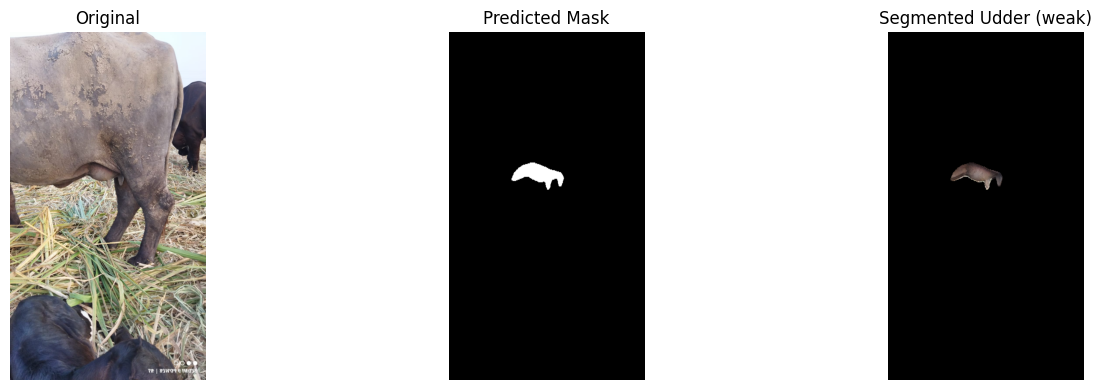

In [ ]:
import cv2
import torch
from torchvision import transforms as T
import segmentation_models_pytorch as smp
from torchvision import models
import numpy as np
import matplotlib.pyplot as plt  # <-- NEW

# --- load seg model (same as before) ---
def load_seg_model(path, device):
    model = smp.Unet("resnet34", encoder_weights=None, in_channels=3, classes=1).to(device)
    state = torch.load(path, map_location=device)
    model.load_state_dict(state)
    model.eval()
    return model

# --- load classifier ---
def load_cls_model(path, device):
    model = models.resnet18(pretrained=False)
    num_ftrs = model.fc.in_features
    model.fc = torch.nn.Linear(num_ftrs, 3)
    state = torch.load(path, map_location=device)
    model.load_state_dict(state)
    model = model.to(device)
    model.eval()
    return model

def crop_to_mask(image, mask, pad=0.12):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0 or len(ys) == 0:
        return image
    h, w = image.shape[:2]
    x_min, x_max = xs.min(), xs.max()
    y_min, y_max = ys.min(), ys.max()
    bw, bh = x_max-x_min+1, y_max-y_min+1
    pw, ph = int(bw*pad), int(bh*pad)
    x_min, x_max = max(0, x_min-pw), min(w-1, x_max+pw)
    y_min, y_max = max(0, y_min-ph), min(h-1, y_max+ph)
    return image[y_min:y_max+1, x_min:x_max+1]

def segment_image(model, image_bgr, img_size=512, device="cuda"):
    img_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    h, w = img_rgb.shape[:2]
    tf = T.Compose([
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225]),
    ])
    img_resized = cv2.resize(img_rgb, (img_size, img_size))
    tensor = tf(img_resized).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = model(tensor)
        probs = torch.sigmoid(logits)[0,0].cpu().numpy()
    mask_small = (probs > 0.5).astype("uint8")*255
    mask = cv2.resize(mask_small, (w, h), interpolation=cv2.INTER_NEAREST)
    return mask


if __name__ == "__main__":
    device = "cuda" if torch.cuda.is_available() else "cpu"
    seg_model = load_seg_model("models/udder/udder_seg_best.pth", device)
    cls_model = load_cls_model("models/udder/udder_cls_best.pth", device)

    label_names = {0: "weak", 1: "average", 2: "strong"}

    img_bgr = cv2.imread(img_path)

    # 1) segmentation
    mask = segment_image(seg_model, img_bgr, img_size=512, device=device)

    # 2) crop ROI
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    crop = crop_to_mask(img_rgb, mask)

    # 3) classify
    tf_cls = T.Compose([
        T.ToPILImage(),
        T.Resize((224, 224)),
        T.ToTensor(),
        T.Normalize(mean=[0.485, 0.456, 0.406],
                    std=[0.229, 0.224, 0.225]),
    ])
    tensor = tf_cls(crop).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = cls_model(tensor)
        pred_idx = int(torch.argmax(logits, dim=1).item())
    print("Predicted fore udder attachment:", label_names[pred_idx])

    # ---------- NOTEBOOK VISUALIZATION PART ----------

    # Binary mask for visualization
    mask_bin = mask > 0

    # Segmented image = keep udder, black-out everything else
    segmented_rgb = img_rgb.copy()
    segmented_rgb[~mask_bin] = 0

    # Optionally, overlay mask in green on original
    overlay = img_rgb.copy()
    overlay[mask_bin] = [0, 255, 0]
    overlay = cv2.addWeighted(img_rgb, 0.6, overlay, 0.4, 0)

    # Show in notebook
    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img_rgb)
    plt.title("Original")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(mask, cmap="gray")
    plt.title("Predicted Mask")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(segmented_rgb)
    plt.title(f"Segmented Udder ({label_names[pred_idx]})")
    plt.axis("off")

    plt.tight_layout()
    plt.show()
